# TP3 — Small data : prédire la popularité d'un morceau Spotify

*Cycle classique **Data → EDA → Prétraitement → Transformation → ML → Éval → Déploiement**, à partir du notebook
Kaggle [Popularity Prediction XGBoost & Regression Analysis](https://www.kaggle.com/code/hosseinfaridnasr/popularity-prediction-xgboost-regression-analysis)
(Hossein Faridnasr), sur le jeu [Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset)
(114 000 morceaux, 114 genres).*

Enzo Caramella — identifiant 24021136 — novembre 2026

## Ma contribution

### Le notebook est-il correct ?

**Oui.** Il s'exécute de bout en bout (*Restart & Run All*) en 4 à 5 minutes, sous Windows 11 avec Python 3.12,
pandas 3, scikit-learn 1.9, XGBoost 3.4 et PySpark 4.2 (Java 21). Les données sont incluses dans
`spotify_tracks_dataset/`, et les dépendances sont listées dans `requirements.txt`.

### Pourquoi ce notebook de départ ?

Parmi les notebooks de l'onglet *Code* du jeu de données, il est l'un des plus clairement structurés : chargement,
prétraitement, EDA, comparaison de neuf modèles, importance des variables, conclusion. Il traite un vrai problème de
ML (régression de la popularité), et pas seulement de la visualisation. Il contient aussi des erreurs instructives à
corriger.

### Problèmes rencontrés dans le notebook d'origine

1. **Il ne s'exécute plus** avec les bibliothèques actuelles. `DataFrame.append` a été supprimé dans pandas 2, et avec
   pandas 3 le texte est de type `str` et non plus `object`. Résultat : `labelencoder` n'encodait plus `track_genre`, et
   `df.corr()` plantait.
2. **Fuite de données** : 21 % des lignes sont des **doublons** (le même morceau classé dans plusieurs genres). L'auteur
   les juge « pas de vrais doublons » et les garde, puis il découpe les lignes au hasard. Résultat : 31 % des lignes de
   test ont leur morceau dans l'apprentissage, et le R² de XGBoost est **surestimé** (0,47 au lieu de 0,32).
3. **Encodage ordinal du genre** (`LabelEncoder`) : il prive les modèles linéaires de leur meilleure variable
   (R² ≈ 0,02).
4. Le `pairplot` sur 114 000 lignes prend plusieurs minutes pour un nuage illisible. Il émettait aussi 256
   avertissements (`palette` sans `hue`).
5. Plusieurs imports sont inutilisés (`statsmodels`, `random`, `time`, `joblib.Parallel`). Le modèle XGBoost est
   réentraîné une seconde fois pour l'importance des variables, et il n'y a ni référence naïve, ni déploiement.

### Modifications apportées

Le code d'origine est conservé et marqué **(origine)**. Chaque ligne modifiée porte un commentaire `# [MODIF]`.

* **Compatibilité** : `pd.concat` à la place de `append`, et détection du texte par `is_string_dtype`. Le chemin
  `/kaggle/input` est remplacé par un chemin local, les graines sont explicites, et les imports inutiles sont retirés.
* **Structure** : sections étiquetées selon le cycle (`## [Data]`, `## [EDA]`… `## [Déploiement]`). L'EDA de la cible
  et des genres est ajoutée, et le `pairplot` porte sur un échantillon de 3 000 lignes.
* **Protocole corrigé**, à côté du protocole d'origine pour comparer : découpage **par morceau** (`GroupShuffleSplit`),
  genre en ***one-hot*** dans un `Pipeline`, et **référence** naïve (moyenne). Les résultats des deux protocoles sont
  comparés.
* **PySpark** (exigé par la consigne) : les mêmes étapes avec Spark. Lecture du CSV, EDA en Spark SQL, découpage par
  morceau, pipeline Spark ML (régression linéaire, forêt aléatoire, GBT), puis comparaison avec scikit-learn.
* **Déploiement** : le pipeline XGBoost est sauvegardé avec `joblib`, accompagné de `config.json` et des métriques. Il
  est rechargé, puis appliqué à un CSV d'exemple (`artefacts/predictions.csv`).

### Autres informations

* Résultat principal sur des morceaux jamais vus : **R² = 0,32, MAE = 14 points** sur 100 (XGBoost comme GBT Spark),
  contre 19 points pour une prédiction constante.
* Le dossier `artefacts/` contient tout ce que le notebook produit : modèle, configuration, métriques, graphiques,
  exemple d'entrée et prédictions.

## Sommaire

Cycle classique : **Data → EDA → Prétraitement → Transformation → ML → Éval → Déploiement**

1. [Configuration] Bibliothèques et chemins
2. [Data] Chargement du jeu *Spotify Tracks Dataset*
3. [EDA] Distribution de la popularité, genres, corrélations
4. [Prétraitement] Nettoyage, encodage et **doublons entre genres**
5. [Transformation] Matrices de features et découpage apprentissage / test
6. [ML] Comparaison de modèles de régression (protocole d'origine, puis protocole corrigé)
7. [Éval] Erreurs, résidus et importance des variables
8. [PySpark] Les mêmes étapes avec Spark (Data, EDA, Prétraitement, Transformation, ML, Éval)
9. [Déploiement] Sauvegarde du pipeline, rechargement et prédiction sur un CSV
10. [Conclusion]

**Notebook de départ** : [*Popularity Prediction XGBoost & Regression Analysis*](https://www.kaggle.com/code/hosseinfaridnasr/popularity-prediction-xgboost-regression-analysis)
(Hossein Faridnasr, Kaggle). Les cellules reprises de ce notebook sont signalées par **(origine)**, et les modifications par
`# [MODIF]`.

## [Configuration] Bibliothèques et chemins

Imports du notebook d'origine, à deux différences près. `statsmodels`, `random`, `time` et `joblib.Parallel`
étaient importés mais **jamais utilisés**, je les ai retirés. J'ai ajouté les outils du protocole corrigé (`GroupShuffleSplit`,
`Pipeline`, `OneHotEncoder`) et du déploiement (`joblib`, `json`).

In [1]:
import os, sys, json, time, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, PolynomialFeatures
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn import linear_model, tree
from sklearn.metrics import mean_squared_error, r2_score
from datetime import datetime
# [MODIF] retirés car inutilisés : statsmodels.variance_inflation_factor, random, time.sleep, joblib.Parallel
# [MODIF] ajouts pour le protocole corrigé et le déploiement
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor
import joblib

pd.set_option('display.max_columns', None)
sns.set(rc={'figure.figsize':(11.7,8.27)})
warnings.filterwarnings("ignore", category=FutureWarning)

DATA = os.path.join("spotify_tracks_dataset", "dataset.csv")     # [MODIF] chemin local au lieu de /kaggle/input/...
ARTEFACTS = "artefacts"
os.makedirs(ARTEFACTS, exist_ok=True)
GRAINE = 0                                                        # graine du notebook d'origine (random_state = 0)
T0 = time.perf_counter()

# Palette sobre et accessible pour les graphiques ajoutés
BLEU, ORANGE, GRIS, ENCRE_2 = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
print("pandas", pd.__version__, "| scikit-learn", __import__("sklearn").__version__, "| xgboost", __import__("xgboost").__version__)

pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1


## [Data] Chargement du jeu *Spotify Tracks Dataset*

[*Spotify Tracks Dataset*](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset) (Maharshi Pandya,
Kaggle, licence BSD) : **114 000 morceaux** récupérés par l'API Spotify, 1 000 par genre pour **114 genres**. Chaque ligne
décrit un morceau dans un genre :

* **cible** : `popularity`, de 0 à 100, calculée par Spotify surtout à partir du **nombre d'écoutes récentes** ;
* **audio** : `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`,
  `valence`, `tempo`, `key`, `mode`, `time_signature`, `duration_ms` ;
* **métadonnées** : `track_id`, `artists`, `album_name`, `track_name`, `explicit`, `track_genre`.

Le fichier (20 Mo) est fourni dans `spotify_tracks_dataset/`.

In [2]:
df = pd.read_csv(DATA)     # (origine) pd.read_csv('/kaggle/input/-spotify-tracks-dataset/dataset.csv')
df_brut = df.copy()        # [MODIF] copie intacte, utilisée par le protocole corrigé et la partie PySpark
print(df.shape)
df.head(3)

(114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,0,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


**(origine)** Doublons et valeurs manquantes, puis suppression des colonnes d'identifiants et de texte :

In [3]:
print(f'number of duplicate rows: {df.duplicated().sum()}\nnumber of null values:\n{df.isna().sum()}')

number of duplicate rows: 0
number of null values:
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [4]:
df.drop(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name'], axis=1, inplace = True)
df.shape

(114000, 16)

In [5]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   popularity        114000 non-null  int64  
 1   duration_ms       114000 non-null  int64  
 2   explicit          114000 non-null  bool   
 3   danceability      114000 non-null  float64
 4   energy            114000 non-null  float64
 5   key               114000 non-null  int64  
 6   loudness          114000 non-null  float64
 7   mode              114000 non-null  int64  
 8   speechiness       114000 non-null  float64
 9   acousticness      114000 non-null  float64
 10  instrumentalness  114000 non-null  float64
 11  liveness          114000 non-null  float64
 12  valence           114000 non-null  float64
 13  tempo             114000 non-null  float64
 14  time_signature    114000 non-null  int64  
 15  track_genre       114000 non-null  str    
dtypes: bool(1), float64(9), int64(5

In [7]:
print(f'number of duplicate rows: {df.duplicated().sum()}\nnumber of null values:\n{df.isna().sum()}')

number of duplicate rows: 7093
number of null values:
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


> **(origine)** *« We can see that we actually have some duplicates but since they were introduced after we removed some
> of our columns they are not actual duplicates and we should keep them in the dataset »*

Cette conclusion est **fausse**, et c'est le principal problème du notebook d'origine. Je le vérifie ci-dessous. Une
même chanson (même `track_id`) apparaît dans **plusieurs genres**, avec les mêmes caractéristiques audio et la même
popularité : ce sont bien de vrais doublons. Seul le genre change, et c'est pourquoi `duplicated()` en trouve si peu.

In [8]:
# [MODIF] Vérification sur les données brutes : combien de morceaux apparaissent dans plusieurs genres ?
par_morceau = df_brut.groupby("track_id").agg(n_genres=("track_genre", "nunique"), n_popularites=("popularity", "nunique"))
print(f"{len(df_brut)} lignes pour {df_brut.track_id.nunique()} morceaux distincts")
print(f"{(par_morceau.n_genres > 1).sum()} morceaux présents dans plusieurs genres (jusqu'à {par_morceau.n_genres.max()})")
print(f"{len(df_brut) - df_brut.track_id.nunique()} lignes en trop, soit {100 * (1 - df_brut.track_id.nunique() / len(df_brut)):.1f} % du jeu")
print(f"Popularité identique dans toutes les copies : {(par_morceau.n_popularites == 1).mean():.1%} des morceaux")
exemple = par_morceau.n_genres.idxmax()
df_brut[df_brut.track_id == exemple][["track_name", "artists", "track_genre", "popularity", "danceability", "energy"]]

114000 lignes pour 89741 morceaux distincts
16299 morceaux présents dans plusieurs genres (jusqu'à 9)
24259 lignes en trop, soit 21.3 % du jeu
Popularité identique dans toutes les copies : 99.2% des morceaux


,track_name,artists,track_genre,popularity,danceability,energy
8315,Baby Blue - Remastered 2010,Badfinger,blues,67,0.623,0.876
19759,Baby Blue - Remastered 2010,Badfinger,country,67,0.623,0.876
34728,Baby Blue - Remastered 2010,Badfinger,folk,67,0.623,0.876
62226,Baby Blue - Remastered 2010,Badfinger,j-pop,67,0.623,0.876
63087,Baby Blue - Remastered 2010,Badfinger,j-rock,67,0.623,0.876
82064,Baby Blue - Remastered 2010,Badfinger,power-pop,67,0.623,0.876
84129,Baby Blue - Remastered 2010,Badfinger,psych-rock,67,0.623,0.876
99727,Baby Blue - Remastered 2010,Badfinger,singer-songwriter,67,0.623,0.876
102732,Baby Blue - Remastered 2010,Badfinger,songwriter,67,0.623,0.876


Ainsi, **21 %** des lignes (24 259) sont des copies d'un morceau déjà présent, à la même popularité pour 99 % d'entre
eux. *Baby Blue* de Badfinger apparaît par exemple dans **9 genres**, de `blues` à `j-rock`.
Avec un découpage aléatoire des lignes, une copie se retrouve dans l'apprentissage et une autre dans le test : le
modèle « reconnaît » le morceau au lieu de prédire sa popularité. Le score de test est alors **trop optimiste**.
J'en mesure l'effet dans les sections ML et Éval.

## [EDA] Distribution de la popularité, genres, corrélations

Le notebook d'origine fait l'EDA **après** l'encodage, avec un `pairplot` et une matrice de corrélation. Je commence
par regarder la cible et les genres sur les données brutes.

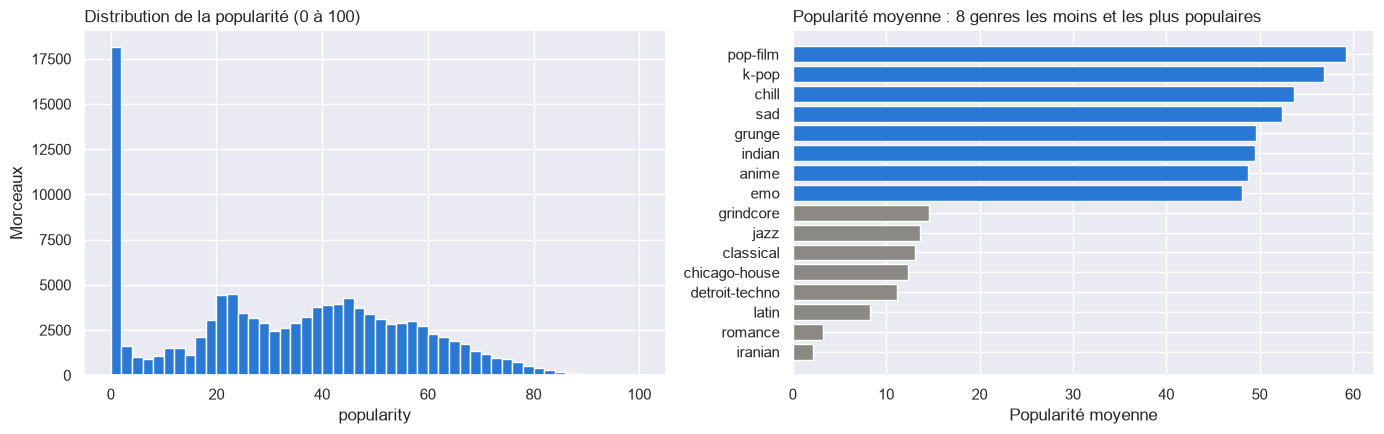

Popularité nulle : 14.1% des lignes ; médiane = 35
Écart entre genres : de 2.2 (iranian) à 59.3 (pop-film)


In [9]:
# [MODIF] Analyse de la cible et des genres (ajout)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df_brut.popularity, bins=50, color=BLEU)
axes[0].set_title("Distribution de la popularité (0 à 100)", loc="left")
axes[0].set_xlabel("popularity"); axes[0].set_ylabel("Morceaux")
moy_genre = df_brut.groupby("track_genre").popularity.mean().sort_values()
extremes = pd.concat([moy_genre.head(8), moy_genre.tail(8)])
axes[1].barh(extremes.index, extremes.values, color=[GRIS] * 8 + [BLEU] * 8)
axes[1].set_title("Popularité moyenne : 8 genres les moins et les plus populaires", loc="left")
axes[1].set_xlabel("Popularité moyenne")
fig.tight_layout(); fig.savefig(os.path.join(ARTEFACTS, "eda.png"), dpi=110); plt.show()
print(f"Popularité nulle : {(df_brut.popularity == 0).mean():.1%} des lignes ; médiane = {df_brut.popularity.median():.0f}")
print(f"Écart entre genres : de {moy_genre.min():.1f} ({moy_genre.idxmin()}) à {moy_genre.max():.1f} ({moy_genre.idxmax()})")

* La popularité est **très dispersée** (médiane 35) avec un pic à **0** pour 14 % des morceaux. Ce sont souvent des
  rééditions ou des doublons d'albums que Spotify ne crédite pas des écoutes.
* Le **genre** est très discriminant : la popularité moyenne va de 2 (`iranian`) à 59 (`pop-film`). C'est la
  variable dont on peut attendre le plus.

**(origine)** Encodage des colonnes texte, puis `pairplot` et matrice de corrélation :

In [10]:
def labelencoder(df):
    for c in df.columns:
        if pd.api.types.is_string_dtype(df[c]):   # [MODIF] pandas 3 : le texte n'a plus le type 'object' mais 'str'
            df[c] = df[c].fillna('N')
            lbl = LabelEncoder()
            lbl.fit(list(df[c].values))
            df[c] = lbl.transform(df[c].values)
    return df

In [11]:
df = labelencoder(df)
df.head()

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,0
1,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,0
2,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,0
3,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,0
4,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,0


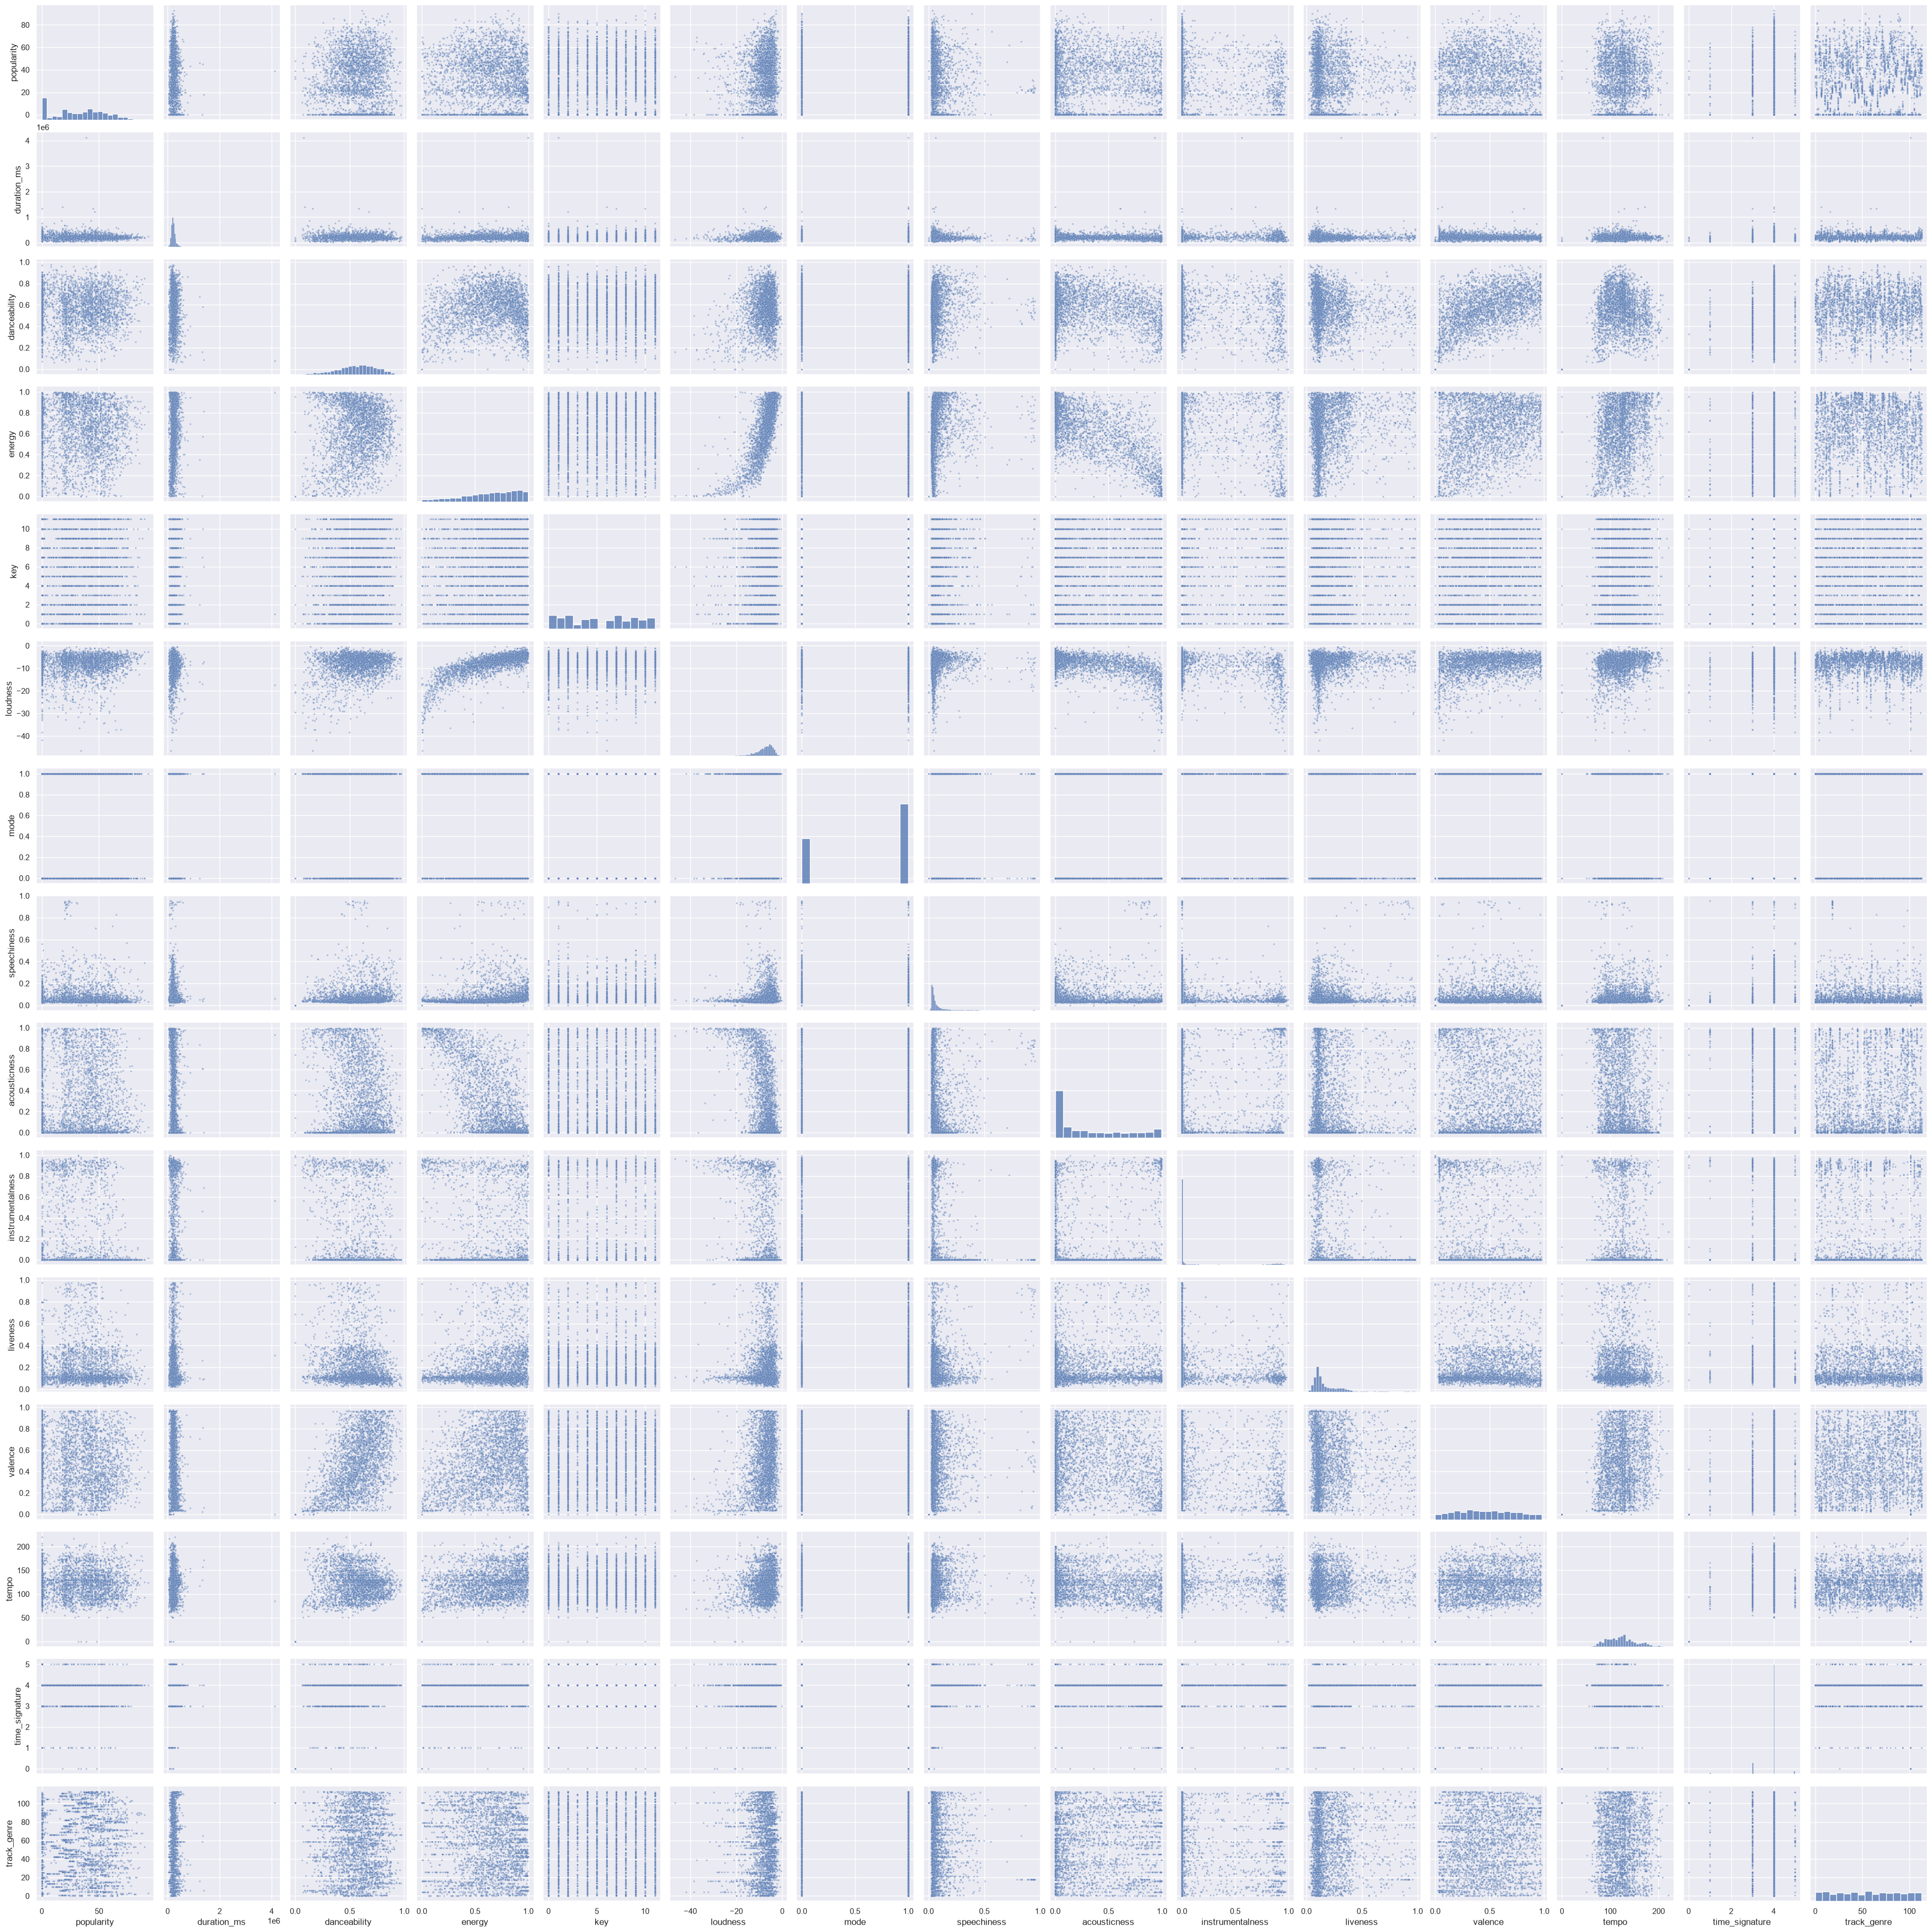

In [12]:
# [MODIF] pairplot sur un échantillon de 3 000 lignes : sur 114 000 lignes x 16 colonnes, il prend plusieurs minutes
#         pour un nuage de points illisible (sur-tracé)
#         palette retirée : sans variable hue, seaborn l'ignore et émet un avertissement par case (256 avertissements)
sns.pairplot(df.sample(3000, random_state=GRAINE).loc[:, (df.dtypes == 'int64') | (df.dtypes == 'float64')],
             plot_kws={"s": 6, "alpha": 0.4})
plt.show()

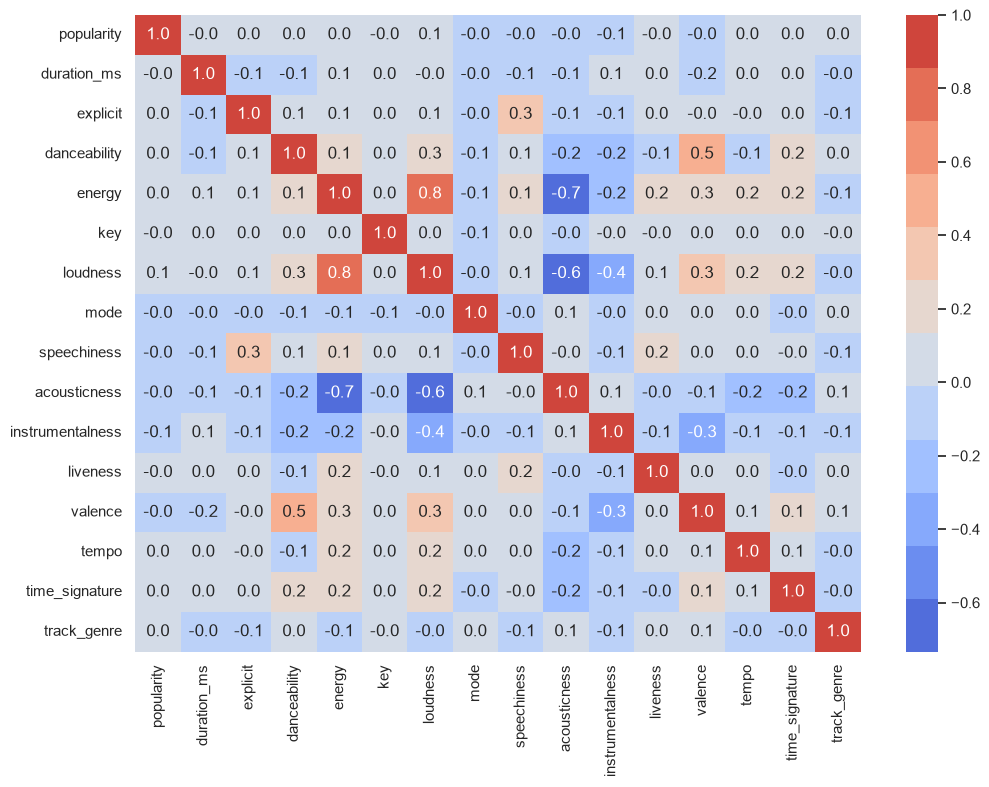

In [13]:
sns.heatmap(df.corr(), annot=True, fmt=".1f", cmap = sns.color_palette("coolwarm", 12))
plt.show()

**Lecture.** Aucune caractéristique audio n'est **linéairement** corrélée à la popularité (|r| ≤ 0,1). On voit en
revanche des corrélations fortes **entre** variables audio : `energy` et `loudness` (0,8), `acousticness` et `energy`
(−0,7). Les modèles linéaires partent donc avec un handicap, et c'est le genre, mal représenté par un encodage ordinal,
qui porte le plus d'information.

> Le `LabelEncoder` transforme `track_genre` en entier (0 à 113, par ordre alphabétique). Pour un modèle linéaire,
> `acoustic` (0) < `afrobeat` (1) < … n'a aucun sens. Seuls les arbres (XGBoost, arbre de décision) peuvent en tirer
> parti, en découpant ces entiers en intervalles.

## [Prétraitement] Nettoyage, encodage et doublons entre genres

Dans le notebook d'origine, le prétraitement se résume aux deux opérations faites plus haut : suppression des colonnes
de texte et encodage ordinal. J'ajoute un **prétraitement corrigé**, utilisé par la suite pour le protocole corrigé :

1. **Supprimer les 3 lignes incomplètes** (`artists`, `album_name` et `track_name` manquants sur la même ligne).
2. **Garder toutes les lignes** (le genre est une information utile), mais **découper par morceau** : toutes les
   copies d'un `track_id` vont du même côté, apprentissage ou test (`GroupShuffleSplit`).
3. **Encoder le genre en *one-hot*** pour les modèles linéaires (114 colonnes 0/1) au lieu d'un entier arbitraire,
   et convertir `explicit` en 0/1.

In [14]:
CIBLE = "popularity"
NUMERIQUES = ["duration_ms", "explicit", "danceability", "energy", "key", "loudness", "mode", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo", "time_signature"]
CATEGORIELLES = ["track_genre"]

propre = df_brut.dropna(subset=["artists", "album_name", "track_name"]).copy()
propre["explicit"] = propre["explicit"].astype(int)
print(f"{len(df_brut) - len(propre)} ligne(s) incomplète(s) supprimée(s) -> {len(propre)} lignes, "
      f"{propre.track_id.nunique()} morceaux")

1 ligne(s) incomplète(s) supprimée(s) -> 113999 lignes, 89740 morceaux


## [Transformation] Matrices de features et découpage apprentissage / test

**(origine)** 80 % / 20 % par tirage aléatoire **des lignes**, sur toutes les colonnes encodées :

In [15]:
X = df.loc[:,df.columns != 'popularity'].values
y = df['popularity'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 0)
print(X_train.shape, X_test.shape)

(91200, 15) (22800, 15)


**[MODIF] Protocole corrigé** : même proportion 80 / 20, mais par **groupe de `track_id`**. On vérifie qu'aucun morceau
n'est des deux côtés. Le genre passe par un `ColumnTransformer` (*one-hot*, plus standardisation des variables
numériques pour les modèles linéaires), intégré à un `Pipeline` : la même transformation sera rejouée telle quelle au
déploiement.

In [16]:
decoupe = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=GRAINE)
i_app, i_test = next(decoupe.split(propre, groups=propre["track_id"]))
app, test = propre.iloc[i_app], propre.iloc[i_test]
communs = set(app.track_id) & set(test.track_id)
print(f"Apprentissage : {len(app)} lignes | Test : {len(test)} lignes | morceaux communs : {len(communs)}")

# Avec le découpage d'origine, combien de lignes de test ont une copie du même morceau dans l'apprentissage ?
i_app0, i_test0 = train_test_split(np.arange(len(df_brut)), test_size=0.2, random_state=0)
vus = set(df_brut.track_id.iloc[i_app0])
print(f"Découpage d'origine : {np.mean([t in vus for t in df_brut.track_id.iloc[i_test0]]):.1%} des lignes de test "
      f"ont leur morceau dans l'apprentissage")

def preparation(echelle=True):
    """One-hot du genre + (option) standardisation des variables numériques."""
    return ColumnTransformer([
        ("genre", OneHotEncoder(handle_unknown="ignore"), CATEGORIELLES),
        ("num", StandardScaler() if echelle else "passthrough", NUMERIQUES),
    ])

X_app, y_app = app[CATEGORIELLES + NUMERIQUES], app[CIBLE].values
X_tst, y_tst = test[CATEGORIELLES + NUMERIQUES], test[CIBLE].values

Apprentissage : 91138 lignes | Test : 22861 lignes | morceaux communs : 0
Découpage d'origine : 31.2% des lignes de test ont leur morceau dans l'apprentissage


## [ML] Comparaison de modèles de régression

### Protocole d'origine

**(origine)** Neuf modèles : XGBoost, Ridge, Lasso, arbre de décision, régression bayésienne, régression linéaire,
et régressions polynomiales de degré 2 et 3.

In [17]:
XGBreg = XGBRegressor(scale_pos_weight=1,
                      learning_rate=0.01,
                      colsample_bytree = 0.3,
                      subsample = 0.8,
                      n_estimators=1000,
                      reg_alpha = 0.3,
                      max_depth=10,
                      gamma=1,
                      random_state=GRAINE, n_jobs=-1)   # [MODIF] graine et parallélisme explicites
ridge_model = linear_model.Ridge(alpha=.5)
lasso_model = linear_model.Lasso(alpha =.1)
tr = tree.DecisionTreeRegressor(random_state=GRAINE)  # [MODIF] graine explicite (reproductibilité)
bayridge_model = linear_model.BayesianRidge()
lm = linear_model.LinearRegression()
poly_list = [PolynomialFeatures(degree=i, include_bias=False) for i in range(2,4)]
prm_list = [linear_model.LinearRegression() for i in range(2,4)]

In [18]:
def model_metrics(model, X_test, y_test, decimals = 5, X_train = X_train, y_train = y_train):
    start  = datetime.now()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = np.round(mean_squared_error(y_test, y_pred),decimals)
    r2 = np.round(r2_score(y_test, y_pred),decimals)
    return {'mean_squared_error': mse, 'R-Squared': r2, 'time': (datetime.now() - start).seconds}

In [19]:
def poly_model_metrics(models, poly_list, X_test, y_test, decimals = 5, X_train = X_train, y_train = y_train):
    metrics_list = []
    for i in range(len(models)):
        start = datetime.now()
        poly_features = poly_list[i].fit_transform(X_train)
        models[i].fit(poly_features, y_train)
        y_pred = models[i].predict(poly_list[i].fit_transform(X_test))
        mse = np.round(mean_squared_error(y_test, y_pred), decimals)
        r2 = np.round(r2_score(y_test, y_pred), decimals)
        metrics_list.append(
            {'mean_squared_error': mse, 'R-Squared': r2, 'time': (datetime.now() - start).seconds})
    return metrics_list

In [20]:
poly_models = poly_model_metrics(prm_list, poly_list, X_test, y_test)
poly_results = pd.DataFrame(
    [
        {'mean_squared_error': metrics['mean_squared_error'], 'R-Squared': metrics['R-Squared'], 'time': metrics['time']}
        for metrics in poly_models
    ],
    index = [f'PolynomiyalRegression_{i+2}_degrees' for i in range(len(poly_models))]) \
.reset_index() \
.rename(columns = {'index': 'model'})

In [21]:
results = pd.DataFrame(
    [
        model_metrics(XGBreg, X_test, y_test),
        model_metrics(ridge_model, X_test, y_test),
        model_metrics(lasso_model, X_test, y_test),
        model_metrics(tr, X_test, y_test),
        model_metrics(bayridge_model, X_test, y_test),
        model_metrics(lm, X_test, y_test)
    ],
    index = ['XGBRegressor', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'BayesianRidge', 'LinearRegression']) \
.reset_index() \
.rename(columns={'index':'model'})

In [22]:
results = pd.concat([results, poly_results])   # [MODIF] DataFrame.append a été supprimé dans pandas 2.0
results.sort_values(['mean_squared_error', 'R-Squared', 'time'],
              ascending = [True, False, True])

,model,mean_squared_error,R-Squared,time
0,XGBRegressor,261.51843,0.47488,21
3,DecisionTreeRegressor,471.63395,0.05297,1
1,Ridge,484.55830,0.02702,0
4,BayesianRidge,484.56537,0.02700,0
5,LinearRegression,486.28013,0.02356,0
2,Lasso,488.06187,0.01998,0
0,PolynomiyalRegression_2_degrees,494.58039,0.00689,1
1,PolynomiyalRegression_3_degrees,497.67949,0.00067,30


Comme dans le notebook d'origine, **XGBoost** l'emporte nettement (R² ≈ 0,47). Tous les modèles linéaires plafonnent
autour de **R² ≈ 0,02** : avec un genre encodé en entier, ils ne peuvent pas exploiter la variable la plus informative.
Les polynômes n'aident pas, et l'arbre de décision non élagué sur-apprend (R² ≈ 0,05).

Mais ce score de XGBoost est **gonflé** : **31 %** des lignes de test ont une copie de leur morceau dans
l'apprentissage (calcul de la section Transformation). XGBoost peut alors retrouver la popularité exacte d'un morceau
déjà vu, en combinant ses caractéristiques audio, qui l'identifient presque à coup sûr.

### [MODIF] Protocole corrigé (découpage par morceau, genre en *one-hot*)

Mêmes familles de modèles et mêmes hyperparamètres, avec une **référence** qui prédit toujours la moyenne. Les
polynômes de degré 2 et 3 sont retirés : ils étaient déjà moins bons que la régression linéaire simple.

In [23]:
modeles = {
    "Référence (moyenne)": Pipeline([("prep", preparation()), ("m", DummyRegressor())]),
    "LinearRegression":    Pipeline([("prep", preparation()), ("m", linear_model.LinearRegression())]),
    "Ridge":               Pipeline([("prep", preparation()), ("m", linear_model.Ridge(alpha=.5))]),
    "DecisionTreeRegressor": Pipeline([("prep", preparation(False)), ("m", tree.DecisionTreeRegressor(random_state=GRAINE))]),
    "XGBRegressor":        Pipeline([("prep", preparation(False)), ("m", XGBRegressor(
        learning_rate=0.01, colsample_bytree=0.3, subsample=0.8, n_estimators=1000, reg_alpha=0.3,
        max_depth=10, gamma=1, random_state=GRAINE, n_jobs=-1))]),
}
lignes, predictions = [], {}
for nom, pipe in modeles.items():
    t = time.perf_counter()
    pipe.fit(X_app, y_app)
    p = pipe.predict(X_tst)
    predictions[nom] = p
    lignes.append({"model": nom, "mean_squared_error": round(mean_squared_error(y_tst, p), 2),
                   "MAE": round(mean_absolute_error(y_tst, p), 2), "R-Squared": round(r2_score(y_tst, p), 4),
                   "time": round(time.perf_counter() - t, 1)})
resultats_corriges = pd.DataFrame(lignes).sort_values("mean_squared_error")
resultats_corriges

,model,mean_squared_error,MAE,R-Squared,time
4,XGBRegressor,338.86,14.00,0.3197,12.8
1,LinearRegression,368.76,14.15,0.2597,0.2
2,Ridge,368.76,14.15,0.2597,0.2
0,Référence (moyenne),498.24,18.92,-0.0003,0.1
3,DecisionTreeRegressor,523.73,14.82,-0.0515,84.1


## [Éval] Erreurs, résidus et importance des variables

**(origine)** Comparaison visuelle des modèles du protocole d'origine (R² ≥ 0) :

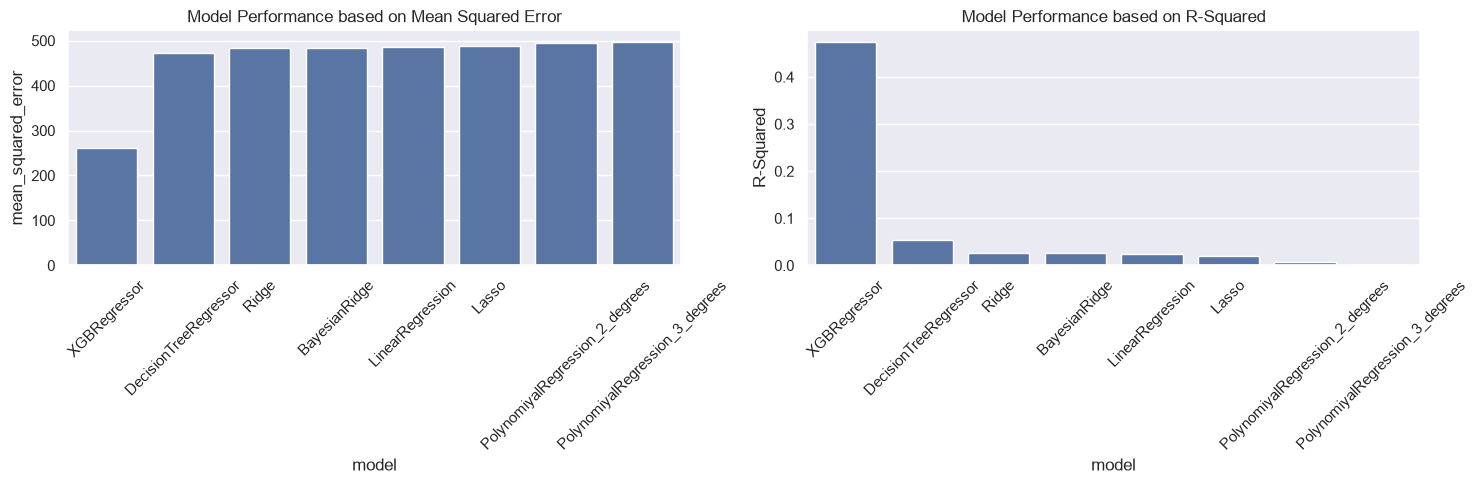

In [24]:
results = results[results['R-Squared'] >= 0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))   # [MODIF] deux graphiques côte à côte
results = results.sort_values('mean_squared_error', ascending = True)
sns.barplot(x = results['model'], y=results['mean_squared_error'], ax=axes[0]).set_title('Model Performance based on Mean Squared Error')
results = results.sort_values('R-Squared', ascending = False)
sns.barplot(x = results['model'], y=results['R-Squared'], ax=axes[1]).set_title('Model Performance based on R-Squared')
for ax in axes: ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); plt.show()

**[MODIF] Effet de la fuite de données** : même modèle, mêmes hyperparamètres, deux protocoles.

In [25]:
r2_origine = results.set_index("model")["R-Squared"]
r2_corrige = resultats_corriges.set_index("model")["R-Squared"]
comparaison = pd.DataFrame({
    "R² protocole d'origine (lignes mélangées)": r2_origine.reindex(["XGBRegressor", "DecisionTreeRegressor", "Ridge", "LinearRegression"]),
    "R² protocole corrigé (par morceau)": r2_corrige.reindex(["XGBRegressor", "DecisionTreeRegressor", "Ridge", "LinearRegression"]),
}).round(3)
comparaison["écart"] = (comparaison.iloc[:, 1] - comparaison.iloc[:, 0]).round(3)
comparaison

,R² protocole d'origine (lignes mélangées),R² protocole corrigé (par morceau),écart
model,,,
XGBRegressor,0.475,0.320,-0.155
DecisionTreeRegressor,0.053,-0.052,-0.105
Ridge,0.027,0.260,0.233
LinearRegression,0.024,0.260,0.236


* **XGBoost perd un tiers de son R²** (0,47 → 0,32) : c'était l'effet de la fuite. Une fois les doublons séparés, il
  reste le meilleur modèle, mais l'écart avec un modèle linéaire devient faible.
* **Les modèles linéaires passent de 0,02 à 0,26** : le *one-hot* leur donne enfin accès au genre, qui suffit à lui
  seul à expliquer l'essentiel de ce qui est prévisible.
* L'arbre de décision non élagué devient **pire que la moyenne** (R² < 0) : sans doublons à reconnaître, son
  sur-apprentissage ne paie plus.

Les chiffres du protocole corrigé sont ceux qu'on peut attendre sur des **morceaux nouveaux**.

**(origine)** Valeurs prédites contre valeurs réelles, et distribution des résidus. Je les calcule pour le
**XGBoost du protocole corrigé** :

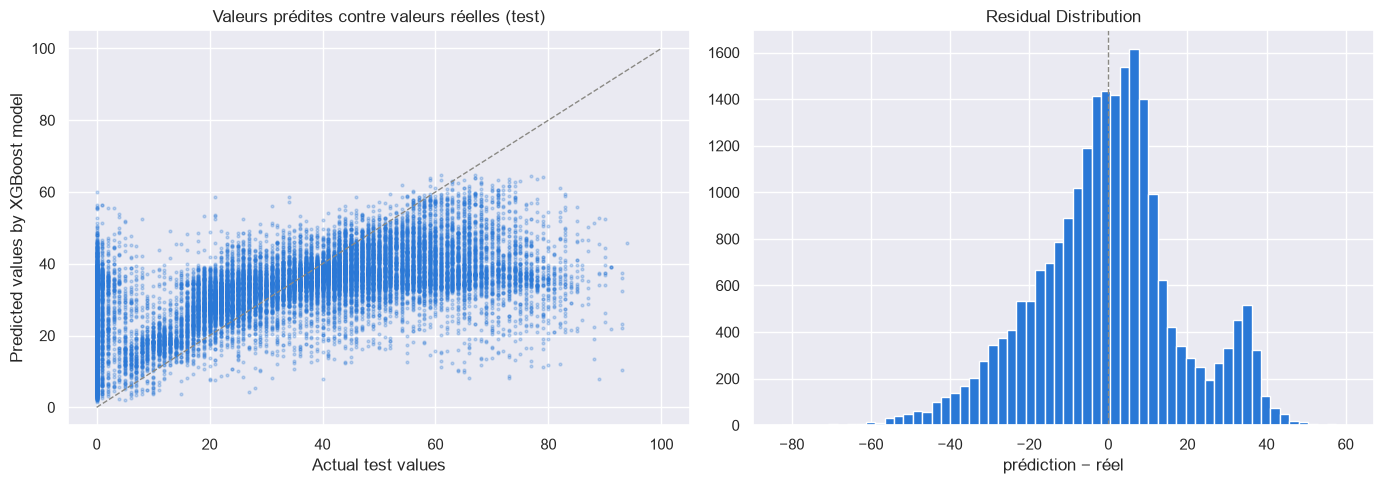

MAE sur les morceaux à popularité 0 : 25.4 | sur les autres : 12.2


In [26]:
y_pred = predictions["XGBRegressor"]                 # [MODIF] XGBoost du protocole corrigé
fig, axes = plt.subplots(1, 2, figsize=(14, 5))      # [MODIF] côte à côte, points semi-transparents
axes[0].scatter(y_tst, y_pred, s=4, alpha=0.25, color=BLEU)
axes[0].plot([0, 100], [0, 100], color=GRIS, ls="--", lw=1)
axes[0].set(xlabel='Actual test values', ylabel='Predicted values by XGBoost model',
            title="Valeurs prédites contre valeurs réelles (test)")
axes[1].hist(y_pred - y_tst, bins=60, color=BLEU)
axes[1].axvline(0, color=GRIS, ls="--", lw=1)
axes[1].set(title='Residual Distribution', xlabel="prédiction − réel")
fig.tight_layout(); fig.savefig(os.path.join(ARTEFACTS, "evaluation.png"), dpi=110); plt.show()
zero = y_tst == 0
print(f"MAE sur les morceaux à popularité 0 : {mean_absolute_error(y_tst[zero], y_pred[zero]):.1f} "
      f"| sur les autres : {mean_absolute_error(y_tst[~zero], y_pred[~zero]):.1f}")

Le modèle **resserre** ses prédictions vers le centre : il sous-estime les tubes et surestime les morceaux peu
écoutés. Les morceaux à **popularité 0** forment une colonne verticale à gauche. L'erreur moyenne y est de **25
points**, contre 12 pour les autres morceaux, car rien dans le son ne distingue une réédition oubliée de son original.
C'est la principale source d'erreur.

**(origine)** Importance des variables pour XGBoost. Je l'affiche pour le modèle du protocole corrigé, en
regroupant les 114 colonnes *one-hot* du genre :

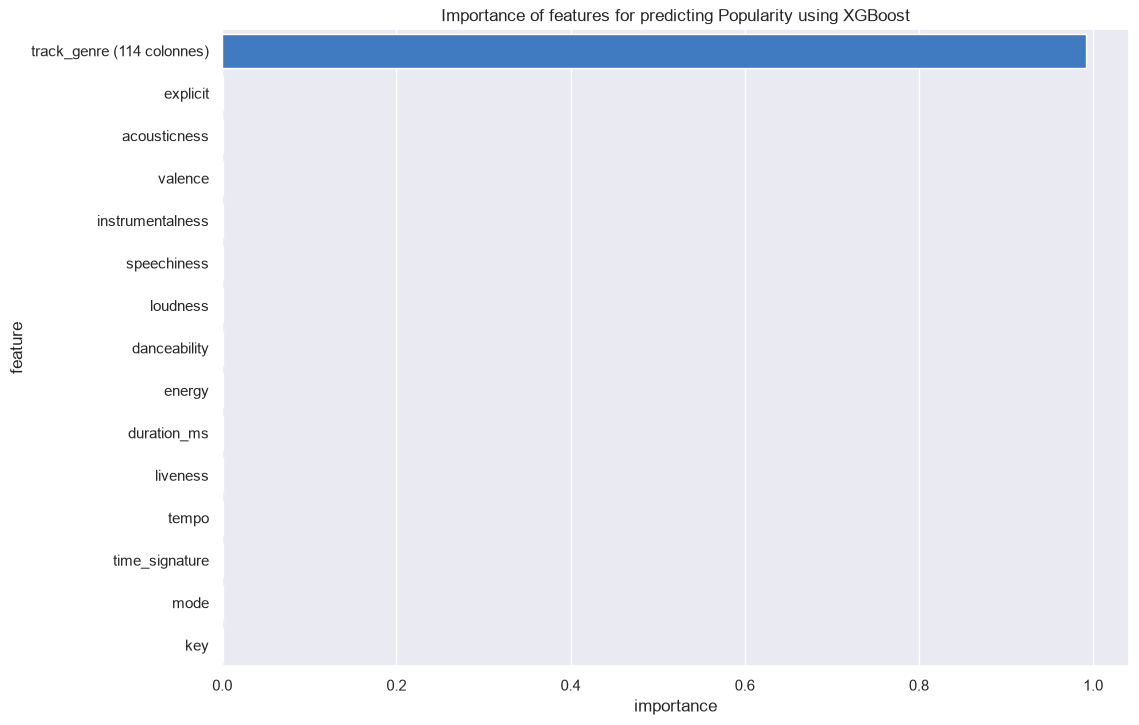

,feature,importance
0,track_genre (114 colonnes),0.9916
1,explicit,0.0011
2,acousticness,0.0008
3,valence,0.0007
4,instrumentalness,0.0006
5,speechiness,0.0006


In [27]:
xgb_model = modeles["XGBRegressor"].named_steps["m"]                       # [MODIF] pas de second entraînement
noms = modeles["XGBRegressor"].named_steps["prep"].get_feature_names_out()
xgb_ftr_imp = xgb_model.feature_importances_
feature_importances_df = (pd.DataFrame({"feature": noms, "importance": xgb_ftr_imp})
                          .assign(feature=lambda d: np.where(d.feature.str.startswith("genre__"), "track_genre (114 colonnes)",
                                                             d.feature.str.replace("num__", "")))
                          .groupby("feature", as_index=False).importance.sum()
                          .sort_values('importance', ascending = False))
sns.barplot(y=feature_importances_df['feature'], x = feature_importances_df['importance'], color=BLEU)\
   .set_title('Importance of features for predicting Popularity using XGBoost')
plt.show()
feature_importances_df.head(6).round(4).reset_index(drop=True)   # [MODIF] valeurs chiffrées

Le **genre** concentre **99 %** de l'importance (gain cumulé des 114 colonnes *one-hot*). Chaque variable audio pèse
individuellement moins de 0,2 %. Avec ces données, savoir dans quel genre un morceau est classé dit beaucoup plus de sa
popularité que tout son profil sonore. Les variables audio n'apportent qu'un complément, par des effets non linéaires
que seul XGBoost capte : c'est l'écart entre son R² (0,32) et celui de la régression linéaire (0,26).

## [PySpark] Les mêmes étapes avec Spark

La consigne demande de traiter aussi les données avec **PySpark** lorsque le notebook d'origine ne l'utilise pas. Cette
section rejoue le cycle avec Spark : lecture, EDA en Spark SQL, prétraitement, découpage par morceau, pipeline
Spark ML et évaluation. Elle permet de comparer les deux écosystèmes sur le même problème.

> Sous Windows, les workers Python lancés par Spark peuvent mourir par intermittence (voir TP2). Cette section n'utilise
> donc que des opérations **exécutées dans la JVM** (DataFrames, SQL, Spark ML), sans UDF Python ni RDD. Le master
> `local[*,4]` autorise en plus 4 essais par tâche.

In [28]:
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder as SparkOneHot, VectorAssembler
from pyspark.ml.regression import GBTRegressor, RandomForestRegressor, LinearRegression as SparkLinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

spark = (SparkSession.builder.master("local[*,4]").appName("TP3 small - Spotify")
         .config("spark.driver.memory", "3g").config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.shuffle.partitions", "16").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "|", spark.sparkContext.defaultParallelism, "threads")

Spark 4.2.0 | 8 threads


### [Data] Lecture du CSV avec Spark

In [29]:
sdf = (spark.read.option("header", True).option("inferSchema", True).option("escape", '"').option("multiLine", True)
       .csv(DATA).drop("_c0"))
sdf.printSchema()
print(sdf.count(), "lignes,", sdf.select("track_id").distinct().count(), "morceaux distincts")

root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- duration_ms: integer (nullable = true)
 |-- explicit: boolean (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- key: integer (nullable = true)
 |-- loudness: double (nullable = true)
 |-- mode: integer (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- time_signature: integer (nullable = true)
 |-- track_genre: string (nullable = true)



114000 lignes, 89741 morceaux distincts


### [EDA] Agrégations en Spark SQL

In [30]:
sdf.createOrReplaceTempView("morceaux")
spark.sql("""
    SELECT track_genre, COUNT(*) AS morceaux, ROUND(AVG(popularity), 1) AS popularite_moyenne,
           ROUND(100 * AVG(CASE WHEN popularity = 0 THEN 1 ELSE 0 END), 1) AS pct_popularite_nulle
    FROM morceaux GROUP BY track_genre ORDER BY popularite_moyenne DESC LIMIT 8
""").show()
spark.sql("""
    SELECT n_genres, COUNT(*) AS morceaux FROM (
        SELECT track_id, COUNT(DISTINCT track_genre) AS n_genres FROM morceaux GROUP BY track_id)
    GROUP BY n_genres ORDER BY n_genres
""").show()

+-----------+--------+------------------+--------------------+
|track_genre|morceaux|popularite_moyenne|pct_popularite_nulle|
+-----------+--------+------------------+--------------------+
|   pop-film|    1000|              59.3|                 0.2|
|      k-pop|    1000|              56.9|                 3.9|
|      chill|    1000|              53.7|                 4.0|
|        sad|    1000|              52.4|                 1.4|
|     grunge|    1000|              49.6|                 3.8|
|     indian|    1000|              49.5|                 1.2|
|      anime|    1000|              48.8|                 0.8|
|        emo|    1000|              48.1|                 4.8|
+-----------+--------+------------------+--------------------+



+--------+--------+
|n_genres|morceaux|
+--------+--------+
|       1|   73442|
|       2|   11424|
|       3|    2955|
|       4|    1361|
|       5|     431|
|       6|     104|
|       7|      21|
|       8|       2|
|       9|       1|
+--------+--------+



Mêmes constats qu'avec pandas : les genres `pop-film`, `k-pop` et `chill` sont en tête, et 16 299 morceaux sont
classés dans plusieurs genres.

### [Prétraitement] Nettoyage et découpage par morceau

On retire les lignes incomplètes, on convertit `explicit` en entier, puis on tire **les morceaux** (et non les lignes)
à 80 / 20. Chaque ligne suit son morceau grâce à une jointure.

In [31]:
sdf_propre = (sdf.dropna(subset=["artists", "album_name", "track_name"])
                 .withColumn("explicit", F.col("explicit").cast("int"))
                 .withColumn("popularity", F.col("popularity").cast("double")))
ids_app, ids_test = sdf_propre.select("track_id").distinct().randomSplit([0.8, 0.2], seed=GRAINE)
s_app = sdf_propre.join(ids_app, "track_id").cache()
s_test = sdf_propre.join(ids_test, "track_id").cache()
print(f"Apprentissage : {s_app.count()} lignes | Test : {s_test.count()} lignes | "
      f"morceaux communs : {s_app.select('track_id').intersect(s_test.select('track_id')).count()}")

Apprentissage : 90926 lignes | Test : 23073 lignes | morceaux communs : 0


### [Transformation] Pipeline Spark ML

`StringIndexer` et `OneHotEncoder` pour le genre, puis `VectorAssembler` pour réunir toutes les features dans un
vecteur.

In [32]:
etapes_prep = [
    StringIndexer(inputCol="track_genre", outputCol="genre_idx", handleInvalid="keep"),
    SparkOneHot(inputCols=["genre_idx"], outputCols=["genre_ohe"]),
    VectorAssembler(inputCols=["genre_ohe"] + NUMERIQUES, outputCol="features"),
]

### [ML] Régression linéaire, forêt aléatoire et gradient boosting (Spark ML)

Les trois modèles sont entraînés sur les mêmes features. Le GBT de Spark est l'équivalent de XGBoost, avec moins
d'options. Je limite sa profondeur à 6 pour garder un temps raisonnable en local.

In [33]:
modeles_spark = {
    "LinearRegression (Spark)": SparkLinearRegression(labelCol="popularity", regParam=0.01),
    "RandomForest (Spark)": RandomForestRegressor(labelCol="popularity", numTrees=100, maxDepth=10, seed=GRAINE),
    "GBT (Spark)": GBTRegressor(labelCol="popularity", maxIter=100, maxDepth=6, stepSize=0.1, seed=GRAINE),
}
evaluateurs = {m: RegressionEvaluator(labelCol="popularity", metricName=m) for m in ["rmse", "mae", "r2"]}
lignes_spark = []
for nom, estimateur in modeles_spark.items():
    t = time.perf_counter()
    modele = SparkPipeline(stages=etapes_prep + [estimateur]).fit(s_app)
    pred = modele.transform(s_test)
    lignes_spark.append({"model": nom, "mean_squared_error": round(evaluateurs["rmse"].evaluate(pred) ** 2, 2),
                         "MAE": round(evaluateurs["mae"].evaluate(pred), 2),
                         "R-Squared": round(evaluateurs["r2"].evaluate(pred), 4), "time": round(time.perf_counter() - t, 1)})

### [Éval] Comparaison scikit-learn / Spark ML (protocole corrigé)

In [34]:
bilan = (pd.concat([resultats_corriges.assign(outil="scikit-learn"), pd.DataFrame(lignes_spark).assign(outil="Spark ML")])
         .sort_values("mean_squared_error").reset_index(drop=True))
bilan

,model,mean_squared_error,MAE,R-Squared,time,outil
0,GBT (Spark),335.14,13.58,0.3198,72.5,Spark ML
1,XGBRegressor,338.86,14.00,0.3197,12.8,scikit-learn
2,LinearRegression (Spark),363.26,14.03,0.2627,4.5,Spark ML
3,LinearRegression,368.76,14.15,0.2597,0.2,scikit-learn
4,Ridge,368.76,14.15,0.2597,0.2,scikit-learn
5,RandomForest (Spark),429.84,17.03,0.1276,43.6,Spark ML
6,Référence (moyenne),498.24,18.92,-0.0003,0.1,scikit-learn
7,DecisionTreeRegressor,523.73,14.82,-0.0515,84.1,scikit-learn


Avec Spark ML, on retrouve **les mêmes conclusions** qu'avec scikit-learn :

* le **GBT de Spark** fait jeu égal avec XGBoost (R² 0,320 dans les deux cas), avec 100 arbres de profondeur 6 au lieu
  de 1 000 arbres de profondeur 10 ;
* la **régression linéaire** de Spark retrouve R² ≈ 0,26 ;
* la **forêt aléatoire** est nettement en dessous (0,13). Ses arbres indépendants, limités à la profondeur 10 et tirés
  sur un tiers des colonnes, exploitent mal les 114 indicatrices de genre.

Le découpage par morceau donne des tailles proches, mais pas identiques : le tirage est différent.

Sur 114 000 lignes, Spark est **plus lent** que scikit-learn : lancement de la JVM, sérialisation, planification des
tâches. Son intérêt apparaît quand les données ne tiennent plus en mémoire sur une machine : c'est le sujet de la
partie *Big* de ce TP.

In [35]:
spark.stop()

## [Déploiement] Sauvegarde du pipeline, rechargement et prédiction sur un CSV

Le modèle retenu est le **pipeline scikit-learn XGBoost du protocole corrigé** : préparation (*one-hot* du genre) et
modèle. Comme il est enregistré d'un seul bloc avec `joblib`, il suffit de lui fournir les colonnes brutes d'un CSV.
Les artefacts produits sont les suivants :

| Fichier | Contenu |
|---|---|
| `artefacts/modele_popularite.joblib` | pipeline complet (préparation + XGBoost) |
| `artefacts/config.json` | colonnes attendues, cible, versions, protocole |
| `artefacts/metriques_test.json` | métriques sur le jeu de test (protocole corrigé) |
| `artefacts/exemple_entree.csv` | 10 morceaux du jeu de test, sans leur popularité |
| `artefacts/predictions.csv` | prédictions du modèle rechargé sur ce CSV |

In [36]:
meilleur = modeles["XGBRegressor"]
chemin_modele = os.path.join(ARTEFACTS, "modele_popularite.joblib")
joblib.dump(meilleur, chemin_modele, compress=3)

metriques = resultats_corriges.set_index("model").loc["XGBRegressor"].to_dict()
config = {
    "modele": "XGBRegressor dans un Pipeline scikit-learn (OneHotEncoder(track_genre) + variables numériques)",
    "cible": CIBLE, "colonnes_entree": CATEGORIELLES + NUMERIQUES,
    "protocole": "GroupShuffleSplit 80/20 par track_id (aucun morceau commun entre apprentissage et test)",
    "versions": {"python": sys.version.split()[0], "scikit-learn": __import__("sklearn").__version__,
                 "xgboost": __import__("xgboost").__version__, "pandas": pd.__version__},
}
json.dump(config, open(os.path.join(ARTEFACTS, "config.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2)
json.dump({"jeu_test_lignes": int(len(test)), "MSE": metriques["mean_squared_error"], "MAE": metriques["MAE"],
           "R2": metriques["R-Squared"]},
          open(os.path.join(ARTEFACTS, "metriques_test.json"), "w", encoding="utf-8"), indent=2)

exemple = test.sample(10, random_state=GRAINE)
exemple[["track_id", "track_name", "artists"] + CATEGORIELLES + NUMERIQUES].to_csv(
    os.path.join(ARTEFACTS, "exemple_entree.csv"), index=False)
print(f"Modèle enregistré : {os.path.getsize(chemin_modele) / 1e6:.1f} Mo")

Modèle enregistré : 7.2 Mo


**Utilisation** : recharger le pipeline et prédire la popularité des morceaux d'un CSV.

In [37]:
def predire_popularite(chemin_csv, chemin_modele=os.path.join(ARTEFACTS, "modele_popularite.joblib"),
                       chemin_sortie=os.path.join(ARTEFACTS, "predictions.csv")):
    """Charge le pipeline sauvegardé et ajoute une colonne popularite_predite au CSV fourni."""
    # joblib repose sur pickle : ne charger que des modèles de confiance (ici, celui produit par ce notebook)
    modele = joblib.load(chemin_modele)
    colonnes = json.load(open(os.path.join(os.path.dirname(chemin_modele), "config.json"), encoding="utf-8"))["colonnes_entree"]
    entree = pd.read_csv(chemin_csv)
    manquantes = set(colonnes) - set(entree.columns)
    if manquantes:
        raise ValueError(f"Colonnes manquantes : {sorted(manquantes)}")
    sortie = entree.assign(popularite_predite=np.clip(modele.predict(entree[colonnes]).astype(float), 0, 100).round(1))
    sortie.to_csv(chemin_sortie, index=False)
    return sortie

sortie = predire_popularite(os.path.join(ARTEFACTS, "exemple_entree.csv"))
sortie[["track_name", "artists", "track_genre", "popularite_predite"]].assign(
    popularite_reelle=exemple["popularity"].values)

,track_name,artists,track_genre,popularite_predite,popularite_reelle
0,Andromeda Mission,Der Dritte Raum,techno,34.8,38
1,Running Away,Hoobastank,grunge,47.9,55
2,cómo dormiste?,Rels B,latino,37.2,89
3,From the Heart,Robert Haig Coxon,new-age,29.8,22
4,Muyè,Rampa;Adam Port;&ME,deep-house,35.3,52
5,Happy Happy,Nacho;Los Mendoza,latino,29.3,0
6,El Charro Viejo,Joan Sebastian,r-n-b,31.6,45
7,secret base ~君がくれたもの~,ZONE,j-idol,28.7,46
8,Dil Diyan Gallan,Vishal-Shekhar;Julius Packiam;Atif Aslam;Irsha...,pop-film,59.2,68
9,Santa Looked a Lot Like Daddy,Travis Tritt,country,15.4,0


Le modèle rechargé fonctionne sans le notebook : un script n'a besoin que de `modele_popularite.joblib`, de
`config.json` et des versions de bibliothèques listées dans `requirements.txt`.

## [Conclusion]

**Ce qu'on peut prédire de la popularité d'un morceau.** Avec seulement son genre et ses caractéristiques audio, le
meilleur modèle explique **environ 32 % de la variance** de la popularité, avec une erreur moyenne de 14 points sur
100, contre 19 pour une prédiction constante. Le **genre** porte presque toute l'information. Le son seul dit très peu
de chose du succès, qui dépend surtout de l'artiste, du marketing, des playlists et de l'ancienneté : autant de
facteurs absents de ces données.

**Ce que la reproduction a révélé.**

* Le notebook d'origine **surestime** ses résultats. Il garde 21 % de doublons (le même morceau dans plusieurs genres)
  et les répartit au hasard entre apprentissage et test. Le R² de 0,47 de XGBoost tombe à **0,32** quand on découpe
  par morceau.
* L'**encodage ordinal** du genre pénalisait les modèles linéaires : un simple *one-hot* fait passer leur R² de 0,02 à
  0,26.
* Il ne fonctionnait plus avec les versions actuelles : `DataFrame.append` a été supprimé dans pandas 2, et le type
  `str` remplace `object` dans pandas 3.
* **Spark ML** retrouve les mêmes conclusions, avec un GBT aussi bon que XGBoost. Sur 114 000 lignes, il est en
  revanche plus lent que scikit-learn : son intérêt commence au-delà de la mémoire d'une machine (partie *Big*).

**Pistes** : intégrer l'artiste (popularité moyenne de ses autres morceaux, calculée sans fuite), traiter à part les
morceaux à popularité 0 (modèle en deux temps : « écouté ou non », puis « combien »), et valider les hyperparamètres
par validation croisée groupée (`GroupKFold`).

In [38]:
print(f"Durée totale d'exécution : {(time.perf_counter() - T0) / 60:.1f} min")

Durée totale d'exécution : 5.5 min
